
# Phase 3 Task 2 — Corrected PyTorch MLP
## House Price Prediction with Controlled Deep Learning Experiments

**Dataset:** `houseprice.csv`  
**Task:** Regression — predict continuous house prices in USD  
**Framework:** PyTorch  
**Evaluation:** R², MAE, RMSE

### Assignment coverage
This notebook implements and explains:
- Multi-Layer Perceptrons (MLPs)
- Forward propagation and backpropagation
- Weight initialization: Zero, Random Normal, Xavier, Kaiming/He
- Regression loss using MSE
- Activation functions: Sigmoid, Tanh, ReLU, LeakyReLU
- Optimizers: SGD + Nesterov momentum, RMSprop, Adam, AdamW
- Dropout and Batch Normalization
- Learning-rate scheduling and early stopping
- Training/validation learning curves
- Model evaluation
- Complete checkpoint saving and reloading

### Important corrections in this version
The workflow is leakage-safe and internally consistent:
1. `price_per_sqft` is excluded because it is derived directly from the target.
2. The data is split **before** categorical encoding and scaling.
3. Repeated properties are kept in the same split using `street` as a grouping key.
4. `OneHotEncoder` is fitted on **training data only** and handles unseen categories.
5. The feature count is determined dynamically — no hard-coded `135` or `138`.
6. Controlled comparisons use the same seeds and batch order.
7. Each experiment is repeated across three seeds and summarized with mean ± standard deviation.
8. Final architecture choices are selected from the validation experiments instead of being hard-coded.
9. The held-out test set is used only after model selection/checkpoint verification.
10. Checkpoints save the model, optimizer, scheduler, epoch, validation loss, and model configuration.



---
## 1. Imports, Reproducibility, and Environment


In [28]:

import os
import copy
import json
import random
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from torch.optim.lr_scheduler import ReduceLROnPlateau

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

import joblib

SEED = 42
EXPERIMENT_SEEDS = [42, 52, 62]

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available()
    else "cpu"
)

Path("checkpoints").mkdir(exist_ok=True)
Path("presentation_graphs").mkdir(exist_ok=True)
Path("artifacts").mkdir(exist_ok=True)

print("=" * 72)
print(f"PyTorch Version : {torch.__version__}")
print(f"Device          : {device}")
print(f"Base Seed       : {SEED}")
print(f"Experiment Seeds: {EXPERIMENT_SEEDS}")
print("=" * 72)



PyTorch Version : 2.11.0
Device          : mps
Base Seed       : 42
Experiment Seeds: [42, 52, 62]



---
## 2. Load, Clean, and Engineer Features

### Leakage prevention
`price_per_sqft` is removed because:

\[
\text{price\_per\_sqft} = \frac{\text{price}}{\text{sqft\_living}}
\]

Using it to predict `price` would directly leak information about the target.

### Redundancy prevention
`sqft_above` is excluded because, in this dataset, it is deterministically related to:

\[
\text{sqft\_living} = \text{sqft\_above} + \text{sqft\_basement}
\]

This reduces perfect linear dependency in classical baselines.


In [29]:

df_raw = pd.read_csv("houseprice.csv")
print(f"Raw dataset shape: {df_raw.shape}")
# Remove non-positive sale prices.
df = df_raw[df_raw["price"] > 0].copy()
removed = len(df_raw) - len(df)



# Parse date and create safe engineered features.
df["sale_date"] = pd.to_datetime(df["date"])
df["sale_month"] = df["sale_date"].dt.month.astype(int)
df["sale_day"] = df["sale_date"].dt.day.astype(int)
df["is_renovated"] = (df["yr_renovated"] > 0).astype(int)
df["living_to_lot_ratio"] = df["sqft_living"] / df["sqft_lot"].clip(lower=1)
df["bath_to_bed_ratio"] = (
    df["bathrooms"] / df["bedrooms"].replace(0, np.nan)
).replace([np.inf, -np.inf], np.nan).fillna(0)

numeric_features = [
    "bedrooms", "bathrooms", "sqft_living", "sqft_lot", "floors",
    "waterfront", "view", "condition", "sqft_basement",
    "yr_built", "yr_renovated",
    "sale_month", "sale_day", "is_renovated",
    "living_to_lot_ratio", "bath_to_bed_ratio",
]
categorical_features = ["city", "statezip"]

print(f"Removed non-positive price rows: {removed}")
print(f"Cleaned dataset shape: {df.shape}")
print(f"Numerical base features: {len(numeric_features)}")
print(f"Categorical features: {categorical_features}")
print("Dropped from modeling: date, sale_date, street, price_per_sqft, sqft_above, price")
df_raw.head()

Raw dataset shape: (4600, 18)
Removed non-positive price rows: 49
Cleaned dataset shape: (4551, 24)
Numerical base features: 16
Categorical features: ['city', 'statezip']
Dropped from modeling: date, sale_date, street, price_per_sqft, sqft_above, price


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,price_per_sqft
0,2014-05-02,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,233.58
1,2014-05-02,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,653.15
2,2014-05-02,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,177.20
3,2014-05-02,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,210.00
4,2014-05-02,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,283.51



---
## 3. Grouped Train / Validation / Test Split — Before Encoding

A normal random row split can place the same property address in both training and test data.  
To prevent that, `street` is used only as a **grouping key** so the same property cannot appear across splits.

Target split:
- ~80% training
- ~10% validation
- ~10% test


In [30]:

# First split: 80% train, 20% temporary.
gss_1 = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
train_pos, temp_pos = next(gss_1.split(df, groups=df["street"]))

train_df = df.iloc[train_pos].copy()
temp_df = df.iloc[temp_pos].copy()

# Second split: temporary data -> 50% validation, 50% test.
gss_2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
val_pos, test_pos = next(gss_2.split(temp_df, groups=temp_df["street"]))

val_df = temp_df.iloc[val_pos].copy()
test_df = temp_df.iloc[test_pos].copy()

train_streets = set(train_df["street"])
val_streets = set(val_df["street"])
test_streets = set(test_df["street"])

assert train_streets.isdisjoint(val_streets)
assert train_streets.isdisjoint(test_streets)
assert val_streets.isdisjoint(test_streets)

print(f"Train: {len(train_df):,} rows")
print(f"Val  : {len(val_df):,} rows")
print(f"Test : {len(test_df):,} rows")
print("Street overlap across splits: 0 ✅")


Train: 3,641 rows
Val  : 455 rows
Test : 455 rows
Street overlap across splits: 0 ✅



---
## 4. Exploratory Data Analysis

The full price distribution is shown on a logarithmic x-axis so luxury outliers are not silently clipped.

The `view` boxplot also uses a logarithmic y-axis so every property remains visible.


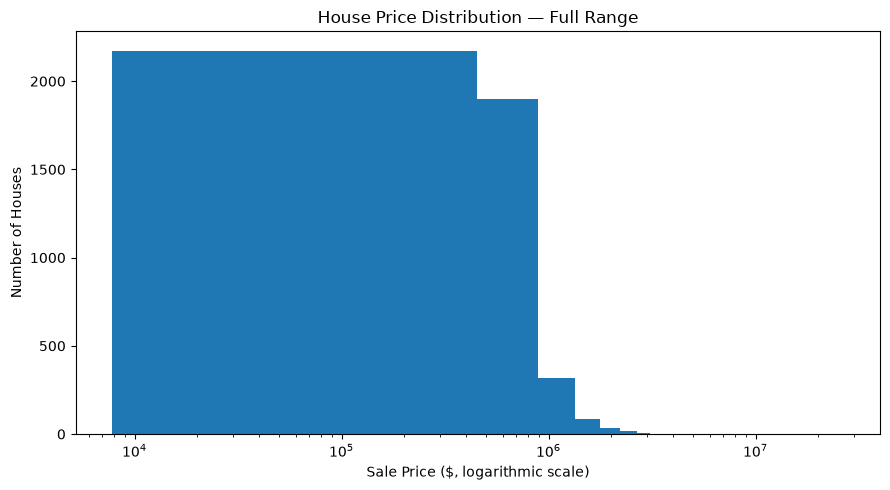

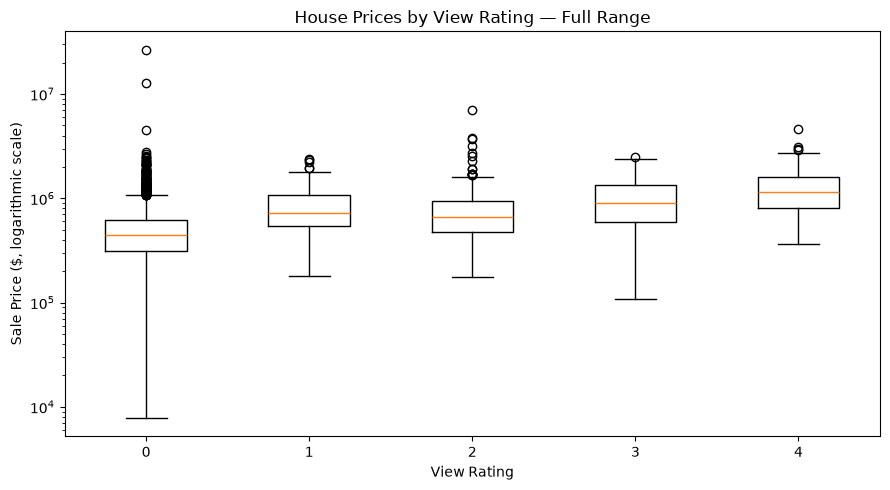

Median View=0 price: $445,000
Median View=4 price: $1,149,000
View=4 / View=0 median ratio: 2.58x


In [31]:

# Price distribution — full data, logarithmic x-axis.
plt.figure(figsize=(9, 5))
plt.hist(df["price"], bins=60)
plt.xscale("log")
plt.xlabel("Sale Price ($, logarithmic scale)")
plt.ylabel("Number of Houses")
plt.title("House Price Distribution — Full Range")
plt.tight_layout()
plt.savefig("presentation_graphs/eda_price_distribution.png", dpi=220, transparent=True)
plt.show()

# View vs price — full data, logarithmic y-axis.
view_groups = [
    df.loc[df["view"] == v, "price"].values
    for v in sorted(df["view"].dropna().unique())
]
view_labels = [str(v) for v in sorted(df["view"].dropna().unique())]

plt.figure(figsize=(9, 5))
plt.boxplot(view_groups, tick_labels=view_labels, showfliers=True)
plt.yscale("log")
plt.xlabel("View Rating")
plt.ylabel("Sale Price ($, logarithmic scale)")
plt.title("House Prices by View Rating — Full Range")
plt.tight_layout()
plt.savefig("presentation_graphs/eda_view_vs_price.png", dpi=220, transparent=True)
plt.show()

view_medians = df.groupby("view")["price"].median()
if 0 in view_medians.index and 4 in view_medians.index:
    ratio = view_medians.loc[4] / view_medians.loc[0]
    print(f"Median View=0 price: ${view_medians.loc[0]:,.0f}")
    print(f"Median View=4 price: ${view_medians.loc[4]:,.0f}")
    print(f"View=4 / View=0 median ratio: {ratio:.2f}x")



---
## 5. Train-Fitted Encoding, Scaling, and DataLoaders

`city` and `statezip` are nominal categorical variables, so one-hot encoding remains a clean choice for this assignment.

The important correction is **when** it is fitted:

> The encoder is fitted on the training split only.

Validation/test categories that were never seen in training are safely handled with `handle_unknown="ignore"`.

For a future PyTorch-specific extension, learned embeddings could replace one-hot encoding.


In [32]:

# Fit categorical encoder ONLY on training data.
encoder = OneHotEncoder(
    handle_unknown="ignore",
    drop="first",
    sparse_output=False,
)
encoder.fit(train_df[categorical_features])

def encode_split(split_df):
    numerical = split_df[numeric_features].to_numpy(dtype=np.float64)
    categorical = encoder.transform(split_df[categorical_features])
    return np.hstack([numerical, categorical])

X_train_raw = encode_split(train_df)
X_val_raw = encode_split(val_df)
X_test_raw = encode_split(test_df)

encoded_names = encoder.get_feature_names_out(categorical_features).tolist()
feature_names = numeric_features + encoded_names
N_FEATURES = len(feature_names)

# Fit scalers ONLY on training data.
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train = scaler_X.fit_transform(X_train_raw).astype(np.float32)
X_val = scaler_X.transform(X_val_raw).astype(np.float32)
X_test = scaler_X.transform(X_test_raw).astype(np.float32)

y_train = scaler_y.fit_transform(train_df[["price"]]).astype(np.float32).ravel()
y_val = scaler_y.transform(val_df[["price"]]).astype(np.float32).ravel()
y_test = scaler_y.transform(test_df[["price"]]).astype(np.float32).ravel()

print(f"Final model input features: {N_FEATURES}")
print(f"X_train shape: {X_train.shape}")
print(f"X_val shape  : {X_val.shape}")
print(f"X_test shape : {X_test.shape}")

def make_loader(X, y, shuffle, seed, batch_size=128):
    generator = torch.Generator()
    generator.manual_seed(seed)
    dataset = TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y, dtype=torch.float32).view(-1, 1),
    )
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        generator=generator,
    )

# Save preprocessing artifacts for later inference.
preprocess_artifacts = {
    "encoder": encoder,
    "scaler_X": scaler_X,
    "scaler_y": scaler_y,
    "feature_names": feature_names,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
}
joblib.dump(preprocess_artifacts, "artifacts/preprocessing.joblib")
print("Saved preprocessing artifacts -> artifacts/preprocessing.joblib")


Final model input features: 134
X_train shape: (3641, 134)
X_val shape  : (455, 134)
X_test shape : (455, 134)
Saved preprocessing artifacts -> artifacts/preprocessing.joblib



---
## 6. PyTorch MLP Architecture

The feature count is now **dynamic** (`N_FEATURES`) instead of hard-coded.

Architecture:

\[
\text{Input} \rightarrow 128 \rightarrow 64 \rightarrow 32 \rightarrow 1
\]

The single output neuron predicts one continuous standardized house-price value.


In [33]:

def get_activation(name):
    name = name.lower()
    if name == "relu":
        return nn.ReLU()
    if name == "leaky_relu":
        return nn.LeakyReLU(negative_slope=0.01)
    if name == "tanh":
        return nn.Tanh()
    if name == "sigmoid":
        return nn.Sigmoid()
    raise ValueError(f"Unknown activation: {name}")

class HousePriceMLP(nn.Module):
    def __init__(
        self,
        in_features,
        hidden_dims=(128, 64, 32),
        activation="relu",
        dropout_rate=0.0,
        use_batchnorm=False,
        out_features=1,
    ):
        super().__init__()

        layers = []
        prev_dim = in_features

        for hidden_dim in hidden_dims:
            layers.append(nn.Linear(prev_dim, hidden_dim))

            if use_batchnorm:
                layers.append(nn.BatchNorm1d(hidden_dim))

            layers.append(get_activation(activation))

            if dropout_rate > 0:
                layers.append(nn.Dropout(dropout_rate))

            prev_dim = hidden_dim

        layers.append(nn.Linear(prev_dim, out_features))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

demo_model = HousePriceMLP(in_features=N_FEATURES)
print(demo_model)


HousePriceMLP(
  (network): Sequential(
    (0): Linear(in_features=134, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): ReLU()
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)



---
## 7. Forward Propagation, Loss, Backpropagation, and Weight Update

For each mini-batch:

```python
optimizer.zero_grad()      # 1. Clear old gradients
predictions = model(x)     # 2. Forward propagation
loss = criterion(predictions, y)  # 3. Measure error
loss.backward()            # 4. Backpropagation
optimizer.step()           # 5. Update weights
```

For this regression task, the training loss is:

```python
criterion = nn.MSELoss()
```

MSE penalizes larger prediction errors more strongly because errors are squared.



---
## 8. Reusable Training and Evaluation Utilities

To make comparisons reproducible:
- every configuration uses the same three seeds;
- each run recreates the same seeded batch order;
- model selection uses the **best validation epoch**, not simply the final epoch;
- the test set is not used during these experiments.


In [34]:

def init_weights(model, method="xavier", activation="relu"):
    for module in model.modules():
        if isinstance(module, nn.Linear):
            if method == "zero":
                nn.init.zeros_(module.weight)

            elif method == "random":
                # Small random baseline; avoids the unrealistic explosion caused by std=1.0.
                nn.init.normal_(module.weight, mean=0.0, std=0.05)

            elif method == "xavier":
                nn.init.xavier_uniform_(module.weight)

            elif method == "kaiming":
                if activation == "leaky_relu":
                    nn.init.kaiming_normal_(
                        module.weight,
                        a=0.01,
                        nonlinearity="leaky_relu",
                    )
                else:
                    nn.init.kaiming_normal_(
                        module.weight,
                        nonlinearity="relu",
                    )
            else:
                raise ValueError(f"Unknown initialization method: {method}")

            if module.bias is not None:
                nn.init.zeros_(module.bias)

def build_optimizer(name, parameters, lr=0.003):
    if name == "SGD":
        return optim.SGD(
            parameters,
            lr=lr,
            momentum=0.9,
            nesterov=True,
        )
    if name == "RMSprop":
        return optim.RMSprop(parameters, lr=lr)
    if name == "Adam":
        return optim.Adam(parameters, lr=lr)
    if name == "AdamW":
        return optim.AdamW(parameters, lr=lr, weight_decay=1e-4)
    raise ValueError(f"Unknown optimizer: {name}")

def evaluate_scaled(model, X, y):
    model.eval()
    with torch.no_grad():
        X_t = torch.tensor(X, dtype=torch.float32, device=device)
        preds = model(X_t).detach().cpu().numpy().ravel()
    return {
        "loss": float(np.mean((preds - y) ** 2)),
        "r2": float(r2_score(y, preds)),
        "preds": preds,
    }

def run_experiment(config, seed, max_epochs=15, patience=4):
    seed_everything(seed)

    model = HousePriceMLP(
        in_features=N_FEATURES,
        hidden_dims=(128, 64, 32),
        activation=config["activation"],
        dropout_rate=config["dropout_rate"],
        use_batchnorm=config["use_batchnorm"],
    ).to(device)

    init_weights(
        model,
        method=config["initialization"],
        activation=config["activation"],
    )

    optimizer = build_optimizer(
        config["optimizer"],
        model.parameters(),
        lr=config.get("lr", 0.003),
    )
    criterion = nn.MSELoss()

    train_loader = make_loader(X_train, y_train, True, seed)
    val_loader = make_loader(X_val, y_val, False, seed)

    history = {"train_loss": [], "val_loss": [], "val_r2": []}

    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0
    counter = 0

    for epoch in range(1, max_epochs + 1):
        model.train()
        train_sum = 0.0
        train_n = 0

        for bx, by in train_loader:
            bx, by = bx.to(device), by.to(device)

            optimizer.zero_grad()
            preds = model(bx)
            loss = criterion(preds, by)
            loss.backward()
            optimizer.step()

            train_sum += loss.item() * len(bx)
            train_n += len(bx)

        train_loss = train_sum / train_n

        model.eval()
        val_sum = 0.0
        val_n = 0
        val_preds = []
        val_targets = []

        with torch.no_grad():
            for bx, by in val_loader:
                bx, by = bx.to(device), by.to(device)
                preds = model(bx)
                loss = criterion(preds, by)

                val_sum += loss.item() * len(bx)
                val_n += len(bx)
                val_preds.append(preds.detach().cpu().numpy())
                val_targets.append(by.detach().cpu().numpy())

        val_loss = val_sum / val_n
        val_preds_np = np.concatenate(val_preds).ravel()
        val_targets_np = np.concatenate(val_targets).ravel()
        val_r2 = r2_score(val_targets_np, val_preds_np)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_r2"].append(val_r2)

        if val_loss < best_val_loss - 1e-5:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            counter = 0
        else:
            counter += 1
            if counter >= patience:
                break

    model.load_state_dict(best_state)

    best_r2 = history["val_r2"][best_epoch - 1]

    return {
        "seed": seed,
        "best_val_loss": best_val_loss,
        "best_val_r2": best_r2,
        "best_epoch": best_epoch,
        "history": history,
        "state_dict": copy.deepcopy(best_state),
    }

def compare_configs(configs, seeds=EXPERIMENT_SEEDS, max_epochs=15):
    summaries = []
    run_store = {}

    for name, config in configs.items():
        runs = [
            run_experiment(config, seed=s, max_epochs=max_epochs)
            for s in seeds
        ]
        run_store[name] = runs

        summaries.append({
            "Configuration": name,
            "Mean Val Loss": np.mean([r["best_val_loss"] for r in runs]),
            "Std Val Loss": np.std([r["best_val_loss"] for r in runs]),
            "Mean Val R2": np.mean([r["best_val_r2"] for r in runs]),
            "Std Val R2": np.std([r["best_val_r2"] for r in runs]),
            "Mean Best Epoch": np.mean([r["best_epoch"] for r in runs]),
        })

    summary_df = pd.DataFrame(summaries).sort_values("Mean Val Loss").reset_index(drop=True)
    return summary_df, run_store

def plot_mean_validation_curves(run_store, title, filename):
    plt.figure(figsize=(9, 5))

    for name, runs in run_store.items():
        max_len = max(len(r["history"]["val_loss"]) for r in runs)
        padded = np.full((len(runs), max_len), np.nan)

        for i, run in enumerate(runs):
            vals = run["history"]["val_loss"]
            padded[i, :len(vals)] = vals

        mean_curve = np.nanmean(padded, axis=0)
        std_curve = np.nanstd(padded, axis=0)
        epochs = np.arange(1, len(mean_curve) + 1)

        plt.plot(epochs, mean_curve, label=name)
        plt.fill_between(
            epochs,
            mean_curve - std_curve,
            mean_curve + std_curve,
            alpha=0.12,
        )

    plt.xlabel("Epoch")
    plt.ylabel("Validation MSE Loss")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.savefig(filename, dpi=220, transparent=True)
    plt.show()



---
## 9. Experiment 1 — Weight Initialization

Controlled settings:
- Activation: ReLU
- Optimizer: Adam
- No Dropout / BatchNorm
- Same seeds and batch ordering
- Best validation epoch used for comparison

`Random` here means **Normal(0, 0.05)** — a reasonable small-random baseline rather than an intentionally explosive `std=1.0`.


,Configuration,Mean Val Loss,Std Val Loss,Mean Val R2,Std Val R2,Mean Best Epoch
0,Random Normal,0.065268,0.001697,0.798835,0.005232,4.000000
1,Kaiming,0.068820,0.000982,0.787888,0.003026,6.666667
2,Xavier,0.077926,0.003075,0.759822,0.009476,7.000000
3,Zero,0.324470,0.000018,-0.000063,0.000055,1.333333


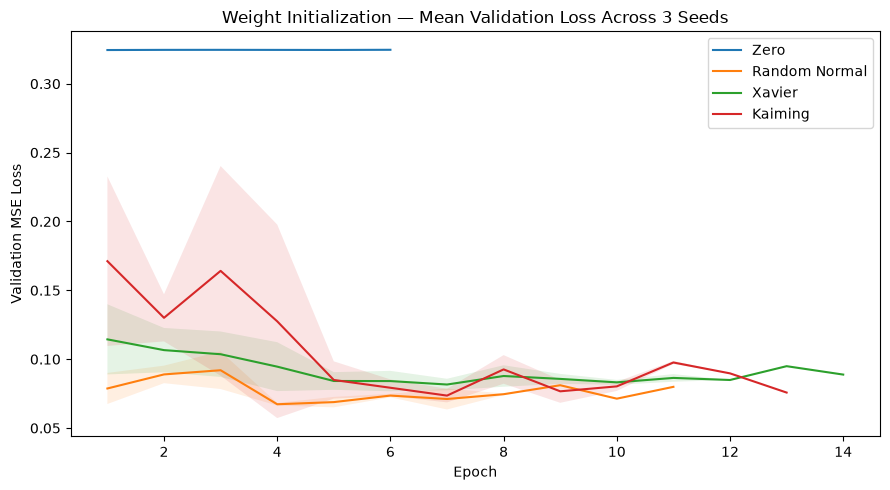

Selected initialization from validation results: Random Normal


In [35]:

init_configs = {
    "Zero": {
        "activation": "relu",
        "dropout_rate": 0.0,
        "use_batchnorm": False,
        "initialization": "zero",
        "optimizer": "Adam",
        "lr": 0.003,
    },
    "Random Normal": {
        "activation": "relu",
        "dropout_rate": 0.0,
        "use_batchnorm": False,
        "initialization": "random",
        "optimizer": "Adam",
        "lr": 0.003,
    },
    "Xavier": {
        "activation": "relu",
        "dropout_rate": 0.0,
        "use_batchnorm": False,
        "initialization": "xavier",
        "optimizer": "Adam",
        "lr": 0.003,
    },
    "Kaiming": {
        "activation": "relu",
        "dropout_rate": 0.0,
        "use_batchnorm": False,
        "initialization": "kaiming",
        "optimizer": "Adam",
        "lr": 0.003,
    },
}

init_summary, init_runs = compare_configs(init_configs)
display(init_summary)

plot_mean_validation_curves(
    init_runs,
    "Weight Initialization — Mean Validation Loss Across 3 Seeds",
    "presentation_graphs/experiment1_weight_initialization.png",
)

best_init_label = init_summary.iloc[0]["Configuration"]
best_init = {
    "Zero": "zero",
    "Random Normal": "random",
    "Xavier": "xavier",
    "Kaiming": "kaiming",
}[best_init_label]

print(f"Selected initialization from validation results: {best_init_label}")



---
## 10. Experiment 2 — Activation Functions

All activation functions use:
- the same architecture;
- the same initialization;
- the same optimizer;
- the same regularization;
- the same seeds and batch order.

Only the activation function changes.


,Configuration,Mean Val Loss,Std Val Loss,Mean Val R2,Std Val R2,Mean Best Epoch
0,relu,0.059013,0.001531,0.818112,0.004719,6.666667
1,leaky_relu,0.059190,0.000756,0.817569,0.002329,7.333333
2,tanh,0.073191,0.001532,0.774414,0.004723,8.333333
3,sigmoid,0.088658,0.000654,0.726743,0.002016,10.666667


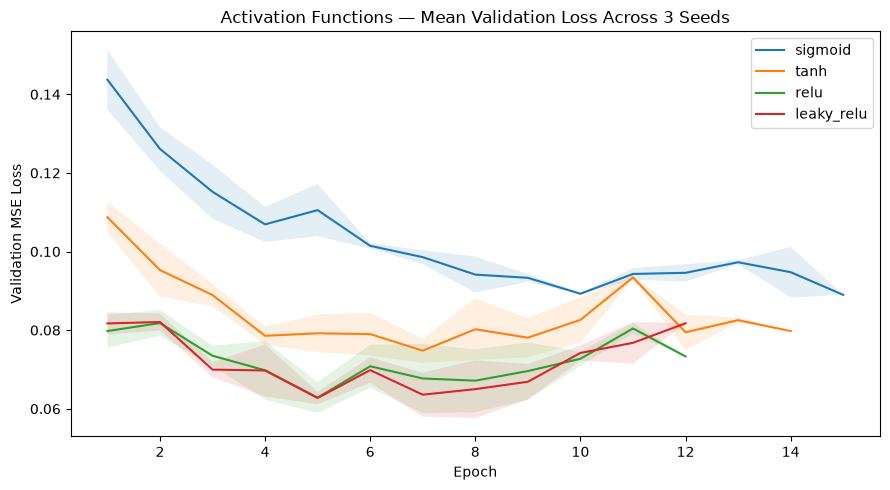

Selected activation from validation results: relu


In [36]:

activation_configs = {}

for activation in ["sigmoid", "tanh", "relu", "leaky_relu"]:
    activation_configs[activation] = {
        "activation": activation,
        "dropout_rate": 0.10,
        "use_batchnorm": True,
        "initialization": best_init,
        "optimizer": "Adam",
        "lr": 0.003,
    }

activation_summary, activation_runs = compare_configs(activation_configs)
display(activation_summary)

plot_mean_validation_curves(
    activation_runs,
    "Activation Functions — Mean Validation Loss Across 3 Seeds",
    "presentation_graphs/experiment2_activation_functions.png",
)

best_activation = activation_summary.iloc[0]["Configuration"]
print(f"Selected activation from validation results: {best_activation}")



---
## 11. Experiment 3 — Optimizers

The optimizer comparison now uses a common learning rate (`0.003`) and identical seeds.

SGD is genuinely configured with **Nesterov momentum**:

```python
optim.SGD(..., momentum=0.9, nesterov=True)
```


,Configuration,Mean Val Loss,Std Val Loss,Mean Val R2,Std Val R2,Mean Best Epoch
0,Adam,0.059013,0.001531,0.818112,0.004719,6.666667
1,AdamW,0.059357,0.003584,0.817052,0.011046,6.666667
2,RMSprop,0.059480,0.003039,0.816674,0.009368,7.000000
3,SGD,0.067830,0.000722,0.790939,0.002225,8.666667


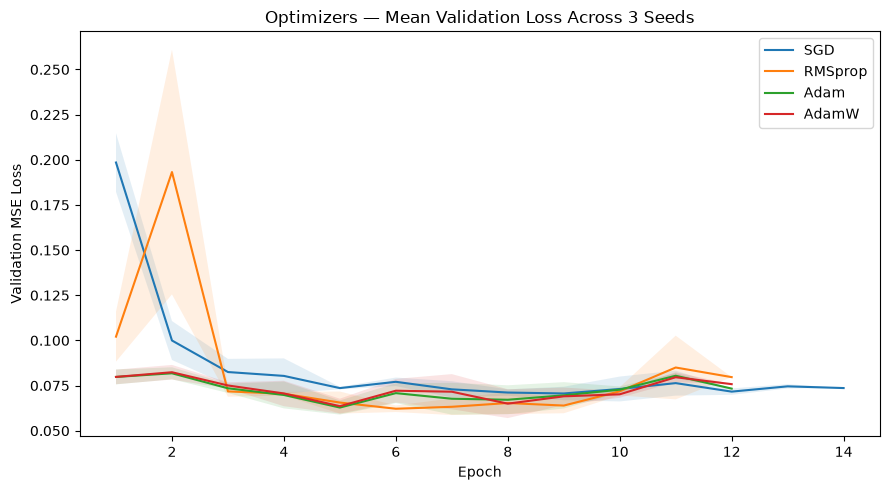

Selected optimizer from validation results: Adam


In [37]:

optimizer_configs = {}

for optimizer_name in ["SGD", "RMSprop", "Adam", "AdamW"]:
    optimizer_configs[optimizer_name] = {
        "activation": best_activation,
        "dropout_rate": 0.10,
        "use_batchnorm": True,
        "initialization": best_init,
        "optimizer": optimizer_name,
        "lr": 0.003,
    }

optimizer_summary, optimizer_runs = compare_configs(optimizer_configs)
display(optimizer_summary)

plot_mean_validation_curves(
    optimizer_runs,
    "Optimizers — Mean Validation Loss Across 3 Seeds",
    "presentation_graphs/experiment3_optimizers.png",
)

best_optimizer = optimizer_summary.iloc[0]["Configuration"]
print(f"Selected optimizer from validation results: {best_optimizer}")



---
## 12. Experiment 4 — Dropout and Batch Normalization

The earlier notebook used a misleading `validation loss − training loss` graph.

That metric is not directly comparable when Dropout and BatchNorm behave differently in `train()` and `eval()` modes.

The corrected experiment compares **validation loss directly**, which answers the real generalization question.


,Configuration,Mean Val Loss,Std Val Loss,Mean Val R2,Std Val R2,Mean Best Epoch
0,Dropout (0.2),0.061206,0.001905,0.811356,0.005872,7.666667
1,BatchNorm + Dropout,0.061370,0.001474,0.810849,0.004543,5.666667
2,Baseline,0.065268,0.001697,0.798835,0.005232,4.000000
3,BatchNorm Only,0.066118,0.005419,0.796215,0.016701,7.000000


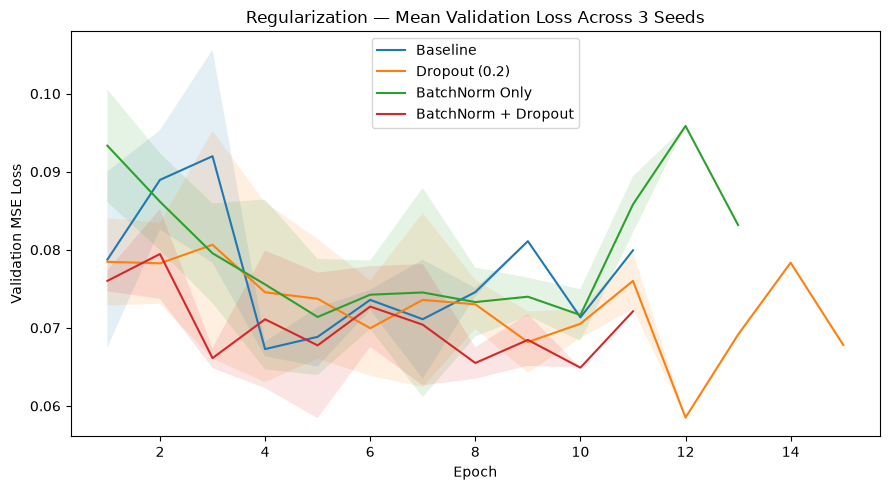

Selected regularization from validation results: Dropout (0.2)


In [38]:

regularization_configs = {
    "Baseline": {
        "activation": best_activation,
        "dropout_rate": 0.0,
        "use_batchnorm": False,
        "initialization": best_init,
        "optimizer": best_optimizer,
        "lr": 0.003,
    },
    "Dropout (0.2)": {
        "activation": best_activation,
        "dropout_rate": 0.20,
        "use_batchnorm": False,
        "initialization": best_init,
        "optimizer": best_optimizer,
        "lr": 0.003,
    },
    "BatchNorm Only": {
        "activation": best_activation,
        "dropout_rate": 0.0,
        "use_batchnorm": True,
        "initialization": best_init,
        "optimizer": best_optimizer,
        "lr": 0.003,
    },
    "BatchNorm + Dropout": {
        "activation": best_activation,
        "dropout_rate": 0.20,
        "use_batchnorm": True,
        "initialization": best_init,
        "optimizer": best_optimizer,
        "lr": 0.003,
    },
}

regularization_summary, regularization_runs = compare_configs(regularization_configs)
display(regularization_summary)

plot_mean_validation_curves(
    regularization_runs,
    "Regularization — Mean Validation Loss Across 3 Seeds",
    "presentation_graphs/experiment4_regularization.png",
)

best_reg_label = regularization_summary.iloc[0]["Configuration"]

if best_reg_label == "Baseline":
    final_dropout, final_batchnorm = 0.0, False
elif best_reg_label == "Dropout (0.2)":
    final_dropout, final_batchnorm = 0.20, False
elif best_reg_label == "BatchNorm Only":
    final_dropout, final_batchnorm = 0.0, True
else:
    final_dropout, final_batchnorm = 0.20, True

print(f"Selected regularization from validation results: {best_reg_label}")



---
## 13. Final Model Configuration — Selected from the Experiments

No activation, optimizer, initialization, or regularization method is hard-coded as the “winner.”

The final configuration is built from the actual validation results above.


In [39]:

final_config = {
    "in_features": N_FEATURES,
    "hidden_dims": (128, 64, 32),
    "activation": best_activation,
    "dropout_rate": final_dropout,
    "use_batchnorm": final_batchnorm,
    "initialization": best_init,
    "optimizer": best_optimizer,
    "lr": 0.003,
}

print("FINAL CONFIGURATION")
print("=" * 60)
for key, value in final_config.items():
    print(f"{key:18s}: {value}")
print("=" * 60)


FINAL CONFIGURATION
in_features       : 134
hidden_dims       : (128, 64, 32)
activation        : relu
dropout_rate      : 0.2
use_batchnorm     : False
initialization    : random
optimizer         : Adam
lr                : 0.003



---
## 14. Final Training — Scheduler, Early Stopping, and Complete Checkpointing

The final model is trained using:
- `ReduceLROnPlateau`
- early stopping
- a complete checkpoint containing model, optimizer, scheduler, epoch, validation loss, and model configuration

The checkpoint is selected using **validation loss only**.


Early stopping triggered at epoch 20
Best validation epoch: 12
Best validation MSE  : 0.058515
Checkpoint saved     : checkpoints/best_houseprice_mlp.pth


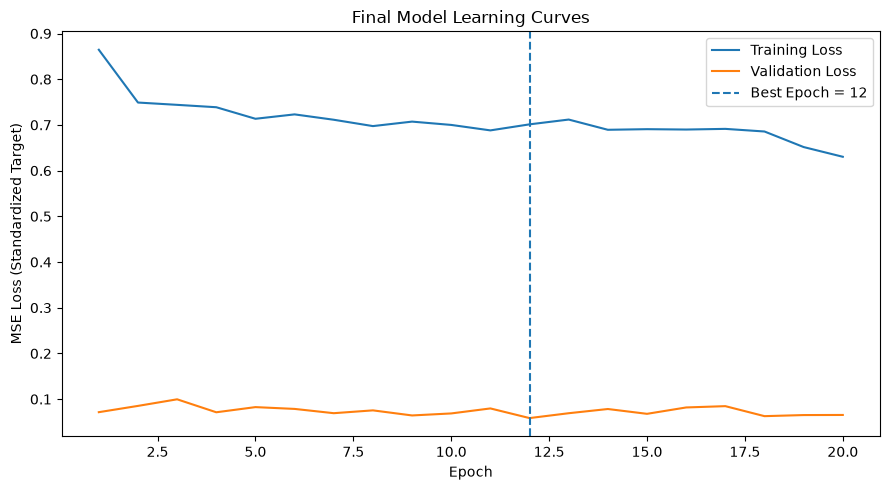

In [40]:

seed_everything(SEED)

final_model = HousePriceMLP(
    in_features=N_FEATURES,
    hidden_dims=final_config["hidden_dims"],
    activation=final_config["activation"],
    dropout_rate=final_config["dropout_rate"],
    use_batchnorm=final_config["use_batchnorm"],
).to(device)

init_weights(
    final_model,
    method=final_config["initialization"],
    activation=final_config["activation"],
)

final_optimizer = build_optimizer(
    final_config["optimizer"],
    final_model.parameters(),
    lr=final_config["lr"],
)

scheduler = ReduceLROnPlateau(
    final_optimizer,
    mode="min",
    factor=0.5,
    patience=4,
    min_lr=1e-5,
)

criterion = nn.MSELoss()
checkpoint_file = "checkpoints/best_houseprice_mlp.pth"

train_loader = make_loader(X_train, y_train, True, SEED)
val_loader = make_loader(X_val, y_val, False, SEED)

MAX_EPOCHS = 60
EARLY_STOPPING_PATIENCE = 8

history = {
    "train_loss": [],
    "val_loss": [],
    "lr": [],
}

best_val_loss = float("inf")
best_epoch = 0
counter = 0

for epoch in range(1, MAX_EPOCHS + 1):
    final_model.train()
    train_sum = 0.0
    train_n = 0

    for bx, by in train_loader:
        bx, by = bx.to(device), by.to(device)

        final_optimizer.zero_grad()
        preds = final_model(bx)
        loss = criterion(preds, by)
        loss.backward()
        final_optimizer.step()

        train_sum += loss.item() * len(bx)
        train_n += len(bx)

    train_loss = train_sum / train_n

    final_model.eval()
    val_sum = 0.0
    val_n = 0

    with torch.no_grad():
        for bx, by in val_loader:
            bx, by = bx.to(device), by.to(device)
            preds = final_model(bx)
            loss = criterion(preds, by)
            val_sum += loss.item() * len(bx)
            val_n += len(bx)

    val_loss = val_sum / val_n
    current_lr = final_optimizer.param_groups[0]["lr"]

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["lr"].append(current_lr)

    scheduler.step(val_loss)

    if val_loss < best_val_loss - 1e-5:
        best_val_loss = val_loss
        best_epoch = epoch
        counter = 0

        torch.save({
            "epoch": epoch,
            "model_state_dict": final_model.state_dict(),
            "optimizer_state_dict": final_optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "validation_loss": best_val_loss,
            "model_config": final_config,
            "feature_names": feature_names,
        }, checkpoint_file)
    else:
        counter += 1

    if counter >= EARLY_STOPPING_PATIENCE:
        print(f"Early stopping triggered at epoch {epoch}")
        break

print(f"Best validation epoch: {best_epoch}")
print(f"Best validation MSE  : {best_val_loss:.6f}")
print(f"Checkpoint saved     : {checkpoint_file}")

plt.figure(figsize=(9, 5))
plt.plot(range(1, len(history["train_loss"]) + 1), history["train_loss"], label="Training Loss")
plt.plot(range(1, len(history["val_loss"]) + 1), history["val_loss"], label="Validation Loss")
plt.axvline(best_epoch, linestyle="--", label=f"Best Epoch = {best_epoch}")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss (Standardized Target)")
plt.title("Final Model Learning Curves")
plt.legend()
plt.tight_layout()
plt.savefig("presentation_graphs/final_model_learning_curves.png", dpi=220, transparent=True)
plt.show()



---
## 15. Reload the Checkpoint and Verify It — Using Validation Data

The earlier notebook touched the test tensor during checkpoint verification.

This corrected version verifies the reloaded model on the **validation set**, keeping the test set untouched until final evaluation.


In [41]:

checkpoint = torch.load(checkpoint_file, map_location=device, weights_only=False)
loaded_config = checkpoint["model_config"]

reloaded_model = HousePriceMLP(
    in_features=loaded_config["in_features"],
    hidden_dims=tuple(loaded_config["hidden_dims"]),
    activation=loaded_config["activation"],
    dropout_rate=loaded_config["dropout_rate"],
    use_batchnorm=loaded_config["use_batchnorm"],
).to(device)

reloaded_model.load_state_dict(checkpoint["model_state_dict"])
reloaded_model.eval()

# Load the same checkpoint into the current model for an exact verification.
final_model.load_state_dict(checkpoint["model_state_dict"])
final_model.eval()

X_val_t = torch.tensor(X_val, dtype=torch.float32, device=device)

with torch.no_grad():
    original_val_preds = final_model(X_val_t)
    reloaded_val_preds = reloaded_model(X_val_t)

is_matching = torch.allclose(
    original_val_preds,
    reloaded_val_preds,
    atol=1e-7,
)

max_difference = (
    original_val_preds - reloaded_val_preds
).abs().max().item()

print(f"Checkpoint epoch       : {checkpoint['epoch']}")
print(f"Saved validation loss  : {checkpoint['validation_loss']:.6f}")
print(f"Reload verification    : {is_matching}")
print(f"Maximum difference     : {max_difference:.2e}")


Checkpoint epoch       : 12
Saved validation loss  : 0.058515
Reload verification    : True
Maximum difference     : 0.00e+00



---
## 16. Final Evaluation on the Held-Out Test Set

The held-out test set is now evaluated **after**:
- preprocessing decisions,
- experiment comparisons,
- final configuration selection,
- early stopping,
- checkpoint verification.

Metrics:
- **R²:** proportion of variance explained;
- **MAE:** average absolute prediction error in USD;
- **RMSE:** square root of the mean squared prediction error in USD.


FINAL HELD-OUT TEST PERFORMANCE — PYTORCH MLP
R²   : 0.7897 (79.0% variance explained)
MAE  : $99,795.11
RMSE : $154,338.79


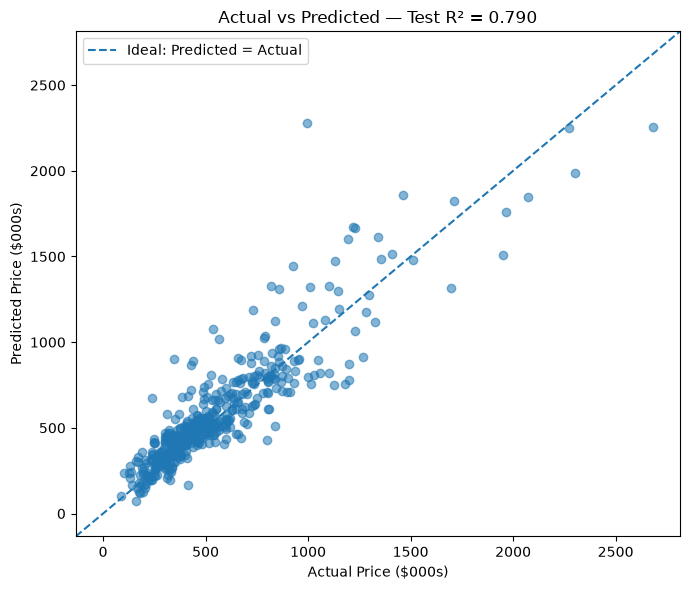

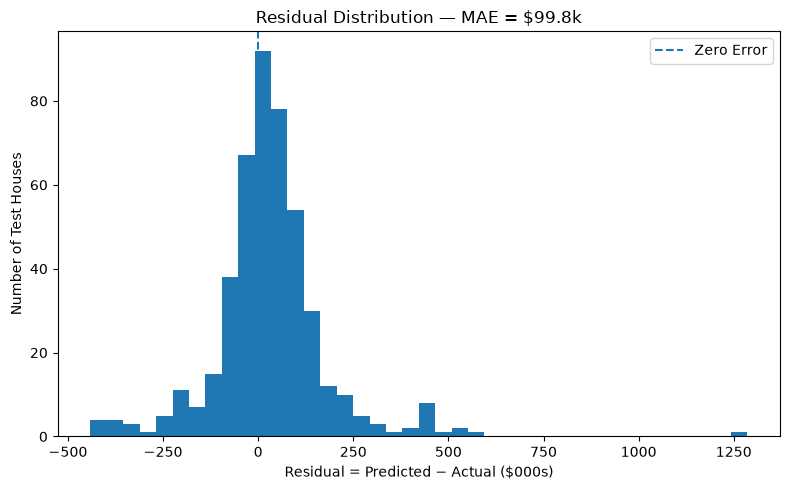

In [42]:

X_test_t = torch.tensor(X_test, dtype=torch.float32, device=device)

reloaded_model.eval()
with torch.no_grad():
    test_pred_scaled = reloaded_model(X_test_t).cpu().numpy().ravel()

test_pred_usd = scaler_y.inverse_transform(
    test_pred_scaled.reshape(-1, 1)
).ravel()

test_actual_usd = test_df["price"].to_numpy(dtype=float)

test_r2 = r2_score(test_actual_usd, test_pred_usd)
test_mae = mean_absolute_error(test_actual_usd, test_pred_usd)
test_rmse = np.sqrt(mean_squared_error(test_actual_usd, test_pred_usd))

print("=" * 68)
print("FINAL HELD-OUT TEST PERFORMANCE — PYTORCH MLP")
print(f"R²   : {test_r2:.4f} ({test_r2 * 100:.1f}% variance explained)")
print(f"MAE  : ${test_mae:,.2f}")
print(f"RMSE : ${test_rmse:,.2f}")
print("=" * 68)

# Dynamic parity range — no hidden luxury observations.
combined_max = max(test_actual_usd.max(), test_pred_usd.max())
combined_min = min(0, test_actual_usd.min(), test_pred_usd.min())
padding = 0.05 * (combined_max - combined_min)
plot_min = combined_min - padding
plot_max = combined_max + padding

plt.figure(figsize=(7, 6))
plt.scatter(test_actual_usd / 1000, test_pred_usd / 1000, alpha=0.55)
plt.plot(
    [plot_min / 1000, plot_max / 1000],
    [plot_min / 1000, plot_max / 1000],
    linestyle="--",
    label="Ideal: Predicted = Actual",
)
plt.xlim(plot_min / 1000, plot_max / 1000)
plt.ylim(plot_min / 1000, plot_max / 1000)
plt.xlabel("Actual Price ($000s)")
plt.ylabel("Predicted Price ($000s)")
plt.title(f"Actual vs Predicted — Test R² = {test_r2:.3f}")
plt.legend()
plt.tight_layout()
plt.savefig("presentation_graphs/prediction_vs_actual_scatter.png", dpi=220, transparent=True)
plt.show()

residuals_usd = test_pred_usd - test_actual_usd

plt.figure(figsize=(8, 5))
plt.hist(residuals_usd / 1000, bins=40)
plt.axvline(0, linestyle="--", label="Zero Error")
plt.xlabel("Residual = Predicted − Actual ($000s)")
plt.ylabel("Number of Test Houses")
plt.title(f"Residual Distribution — MAE = ${test_mae/1000:,.1f}k")
plt.legend()
plt.tight_layout()
plt.savefig("presentation_graphs/prediction_residual_distribution.png", dpi=220, transparent=True)
plt.show()



---
## 17. Reference Benchmark Against Classical Regression Models

This is a **reference comparison**, not a claim of exhaustive hyperparameter optimization.

All models use:
- the same grouped train/test split;
- the same leakage-safe encoded feature matrix;
- the same standardized target.

This wording avoids overstating “fairness” when the MLP received more architecture experimentation.


,Model,R2,MAE,RMSE
0,PyTorch MLP,0.7897,"$99,795","$154,339"
1,SVR,0.7810,"$92,574","$157,476"
2,Ridge Regression,0.7739,"$104,436","$160,024"
3,Linear Regression,0.7728,"$105,005","$160,405"
4,Gradient Boosting,0.6420,"$136,198","$201,351"
5,Random Forest,-0.1568,"$129,315","$361,934"
6,Decision Tree,-0.8104,"$177,336","$452,784"


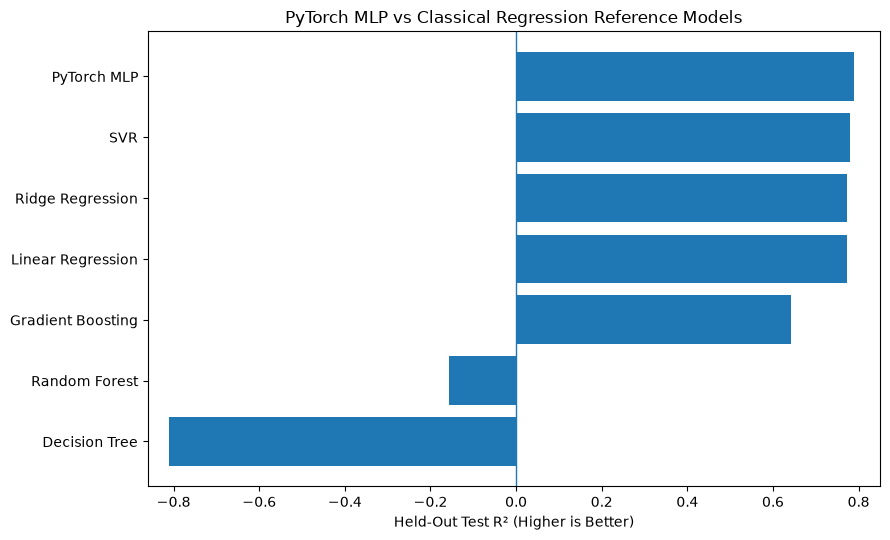

In [46]:

benchmark_models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=10.0),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=10,
        min_samples_leaf=5,
        random_state=SEED,
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=SEED,
        n_jobs=1,
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=250,
        learning_rate=0.03,
        max_depth=2,
        random_state=SEED,
    ),
    "SVR": SVR(C=10.0, epsilon=0.1),
}

benchmark_rows = [{
    "Model": "PyTorch MLP",
    "R2": test_r2,
    "MAE": test_mae,
    "RMSE": test_rmse,
}]

for name, model in benchmark_models.items():
    model.fit(X_train, y_train)
    pred_scaled = model.predict(X_test)

    pred_usd = scaler_y.inverse_transform(
        np.asarray(pred_scaled).reshape(-1, 1)
    ).ravel()

    benchmark_rows.append({
        "Model": name,
        "R2": r2_score(test_actual_usd, pred_usd),
        "MAE": mean_absolute_error(test_actual_usd, pred_usd),
        "RMSE": np.sqrt(mean_squared_error(test_actual_usd, pred_usd)),
    })

benchmark_df = (
    pd.DataFrame(benchmark_rows)
    .sort_values("R2", ascending=False)
    .reset_index(drop=True)
)

display(
    benchmark_df.style.format({
        "R2": "{:.4f}",
        "MAE": "${:,.0f}",
        "RMSE": "${:,.0f}",
    })
)

# Dynamic x-limits show negative R² values if they occur.
r2_min = min(-0.05, benchmark_df["R2"].min() - 0.05)
r2_max = max(0.85, benchmark_df["R2"].max() + 0.05)

plt.figure(figsize=(9, 5.5))
plt.barh(benchmark_df["Model"], benchmark_df["R2"])
plt.axvline(0, linewidth=1)
plt.xlim(r2_min, r2_max)
plt.xlabel("Held-Out Test R² (Higher is Better)")
plt.title("PyTorch MLP vs Classical Regression Reference Models")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("presentation_graphs/benchmark_classical_vs_deep_learning.png", dpi=220, transparent=True)
plt.show()



---
## 18. Held-Out Example Predictions

These examples are selected from the **test split**, not from training data.

They are presented as held-out prediction examples rather than “live inference.”


In [44]:

test_demo = test_df.copy()
test_demo["prediction"] = test_pred_usd
test_demo["abs_error"] = np.abs(test_demo["prediction"] - test_demo["price"])

# Choose one low-view and one highest-view example available in the test set.
low_view_candidates = test_demo[test_demo["view"] == test_demo["view"].min()]
high_view_candidates = test_demo[test_demo["view"] == test_demo["view"].max()]

examples = [
    ("Low-View Held-Out Home", low_view_candidates.iloc[0]),
    ("High-View Held-Out Home", high_view_candidates.iloc[0]),
]

for label, row in examples:
    pct_error = abs(row["prediction"] - row["price"]) / row["price"] * 100

    print("=" * 72)
    print(label)
    print(f"City / Zipcode : {row['city']} ({row['statezip']})")
    print(f"View Rating    : {int(row['view'])} / 4")
    print(f"Waterfront     : {int(row['waterfront'])}")
    print(f"Actual Price   : ${row['price']:,.2f}")
    print(f"Prediction     : ${row['prediction']:,.2f}")
    print(f"Absolute Error : ${row['abs_error']:,.2f} ({pct_error:.1f}%)")


Low-View Held-Out Home
City / Zipcode : Maple Valley (WA 98038)
View Rating    : 0 / 4
Waterfront     : 0
Actual Price   : $482,000.00
Prediction     : $408,515.75
Absolute Error : $73,484.25 (15.2%)
High-View Held-Out Home
City / Zipcode : Shoreline (WA 98177)
View Rating    : 4 / 4
Waterfront     : 0
Actual Price   : $1,000,000.00
Prediction     : $795,123.81
Absolute Error : $204,876.19 (20.5%)



---
## 19. Final Project Summary

This notebook now satisfies the assignment while keeping the methodology internally consistent.

The most important interpretation rule is:

> **Experiment winners are claims about this dataset and this experimental setup — not universal rules for every neural network.**

Examples:
- Xavier may perform best here, but Kaiming is still a standard choice for ReLU-family networks.
- One optimizer may win here without being universally “better.”
- Dropout/BatchNorm usefulness depends on the data and architecture.


In [45]:

best_benchmark_row = benchmark_df.iloc[0]

print("PROJECT SUMMARY")
print("=" * 72)
print(f"Rows after cleaning      : {len(df):,}")
print(f"Input features           : {N_FEATURES}")
print(f"Train / Val / Test       : {len(train_df):,} / {len(val_df):,} / {len(test_df):,}")
print(f"Best initialization      : {best_init_label}")
print(f"Best activation          : {best_activation}")
print(f"Best optimizer           : {best_optimizer}")
print(f"Best regularization      : {best_reg_label}")
print(f"Final PyTorch Test R²    : {test_r2:.4f}")
print(f"Final PyTorch Test MAE   : ${test_mae:,.0f}")
print(f"Final PyTorch Test RMSE  : ${test_rmse:,.0f}")
print(f"Top reference benchmark  : {best_benchmark_row['Model']} (R²={best_benchmark_row['R2']:.4f})")
print("=" * 72)

# Save machine-readable summary.
summary_payload = {
    "n_rows": int(len(df)),
    "n_features": int(N_FEATURES),
    "train_rows": int(len(train_df)),
    "val_rows": int(len(val_df)),
    "test_rows": int(len(test_df)),
    "best_initialization": str(best_init_label),
    "best_activation": str(best_activation),
    "best_optimizer": str(best_optimizer),
    "best_regularization": str(best_reg_label),
    "test_r2": float(test_r2),
    "test_mae": float(test_mae),
    "test_rmse": float(test_rmse),
}

with open("artifacts/final_results.json", "w", encoding="utf-8") as f:
    json.dump(summary_payload, f, indent=2)

print("Saved summary -> artifacts/final_results.json")


PROJECT SUMMARY
Rows after cleaning      : 4,551
Input features           : 134
Train / Val / Test       : 3,641 / 455 / 455
Best initialization      : Random Normal
Best activation          : relu
Best optimizer           : Adam
Best regularization      : Dropout (0.2)
Final PyTorch Test R²    : 0.7897
Final PyTorch Test MAE   : $99,795
Final PyTorch Test RMSE  : $154,339
Top reference benchmark  : PyTorch MLP (R²=0.7897)
Saved summary -> artifacts/final_results.json
